In [2]:
#uninstall tensorflow
!pip uninstall tensorflow

^C


In [1]:
import tensorflow as tf
import sklearn
import pandas as pd
import numpy as np

ImportError: DLL load failed while importing _pywrap_tf2: The specified module could not be found.

In [ ]:
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

In [ ]:
from datasets import load_dataset

# Load Huggingface Dataset
dataset = load_dataset("SetFit/bbc-news")

In [ ]:
# Load Train Dataset
train = dataset["train"].to_pandas()

# Load Test Dataset
test = dataset["test"].to_pandas()

In [ ]:
print("\nMissing values:")
print("Training:")
print(train[["text", "label"]].isnull().sum())
print("Testing:")
print(test[["text", "label"]].isnull().sum())


Missing values:
Training:
text     0
label    0
dtype: int64
Testing:
text     0
label    0
dtype: int64


### Mapping Label
0 : tech

1 : business

2 : sport

3 : entertainment

4 : politics

In [ ]:
print("\nTraining label mapping:")
print(
    train[["label", "label_text"]]
    .drop_duplicates()
    .sort_values("label")
)


Training label mapping:
   label     label_text
4      0           tech
1      1       business
0      2          sport
2      3  entertainment
5      4       politics


In [ ]:
# Validation Split
from sklearn.model_selection import train_test_split

X = train["text"].to_numpy()
y = train["label"].to_numpy()

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
    stratify=y
)

X_test = test["text"].to_numpy()
y_test = test["label"].to_numpy()

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 980
Validation: 245
Testing: 1000


In [ ]:
MAX_WORDS = 10000
MAX_LEN = 300

tokenizer = tf.keras.preprocessing.text.Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = tf.keras.preprocessing.sequence.pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val_pad = tf.keras.preprocessing.sequence.pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = tf.keras.preprocessing.sequence.pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training input shape:", X_train_pad.shape)
print("Validation input shape:", X_val_pad.shape)
print("Test input shape:", X_test_pad.shape)
print("Vocabulary size:", min(len(tokenizer.word_index) + 1, MAX_WORDS))

Training input shape: (980, 300)
Validation input shape: (245, 300)
Test input shape: (1000, 300)
Vocabulary size: 10000


In [ ]:
NUM_CLASSES = train["label"].nunique()

print("Number of classes:", NUM_CLASSES)
print("Training labels:", np.unique(y_train))
print("Test labels:", np.unique(y_test))

majority_baseline = np.bincount(y_train).max() / len(y_train)
print(f"Majority-class baseline: {majority_baseline:.4f} ({majority_baseline * 100:.2f}%)")

Number of classes: 5
Training labels: [0 1 2 3 4]
Test labels: [0 1 2 3 4]
Majority-class baseline: 0.2337 (23.37%)


# LSTM

In [ ]:
# LSTM classifier with regularization

embedding_vector_dim = 64
model = tf.keras.Sequential()

model.add(tf.keras.layers.Input(shape=(MAX_LEN,)))

model.add(tf.keras.layers.Embedding(
    input_dim=MAX_WORDS,
    output_dim=embedding_vector_dim,
    mask_zero=True
))

model.add(tf.keras.layers.SpatialDropout1D(0.2))
model.add(tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64)))
model.add(tf.keras.layers.Dropout(0.4))

model.add(tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"))

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

In [ ]:
model.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_13 (Embedding)        │ (None, 300, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_8             │ (None, 300, 64)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_8 (Bidirectional) │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 706,693 (2.70 MB)

 Trainable params: 706,693 (2.70 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    batch_size=32,
    epochs=30,
    validation_data=(X_val_pad, y_val),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 14s 126ms/step - accuracy: 0.2541 - loss: 1.5975 - val_accuracy: 0.2327 - val_loss: 1.5699
Epoch 2/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 4s 118ms/step - accuracy: 0.5092 - loss: 1.3558 - val_accuracy: 0.5633 - val_loss: 1.1389
Epoch 3/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 4s 121ms/step - accuracy: 0.6643 - loss: 0.9318 - val_accuracy: 0.8122 - val_loss: 0.7298
Epoch 4/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - accuracy: 0.8806 - loss: 0.4698 - val_accuracy: 0.8694 - val_loss: 0.4603
Epoch 5/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - accuracy: 0.9520 - loss: 0.1986 - val_accuracy: 0.8694 - val_loss: 0.4330
Epoch 6/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 103ms/step - accuracy: 0.9571 - loss: 0.2238 - val_accuracy: 0.8898 - val_loss: 0.4730
Epoch 7/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 4s 137ms/step - accuracy: 0.9786 - loss: 0.1564 - val_accuracy: 0.9265 - val_loss: 0.2496
Epoch 8/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 8s 268ms/step - accuracy: 0.9949 - loss: 0.0368 - val_accuracy: 0

In [ ]:
# save model
model.save("lstm_model.keras")

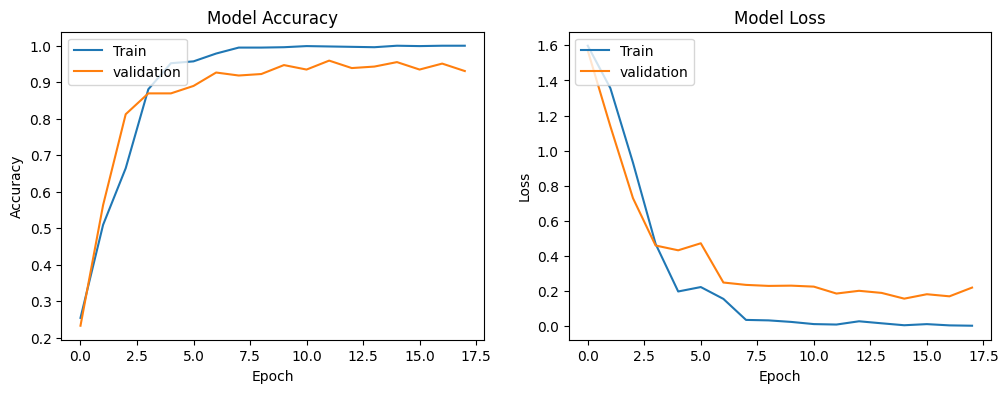

In [ ]:
#plot

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'validation'], loc='upper left')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'validation'], loc='upper left')

plt.show()

In [ ]:
#evaluation

test_loss, test_accuracy = model.evaluate(X_test_pad, y_test, verbose=0)
print(f"Test Loss: {test_loss}, Test Accuracy: {test_accuracy}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

y_pred = model.predict(X_test_pad)

y_pred_classes = np.argmax(y_pred, axis=1)

Test Loss: 0.2470804750919342, Test Accuracy: 0.9380000233650208
Test Accuracy: 93.80%
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step


Test Loss: 0.2471
Test Accuracy: 0.9380
Test Accuracy: 93.80%

Classification Report:
               precision    recall  f1-score   support

         tech       0.89      0.94      0.92       189
     business       0.91      0.96      0.93       224
        sport       0.98      0.98      0.98       236
entertainment       0.95      0.90      0.93       176
     politics       0.96      0.89      0.92       175

     accuracy                           0.94      1000
    macro avg       0.94      0.93      0.94      1000
 weighted avg       0.94      0.94      0.94      1000



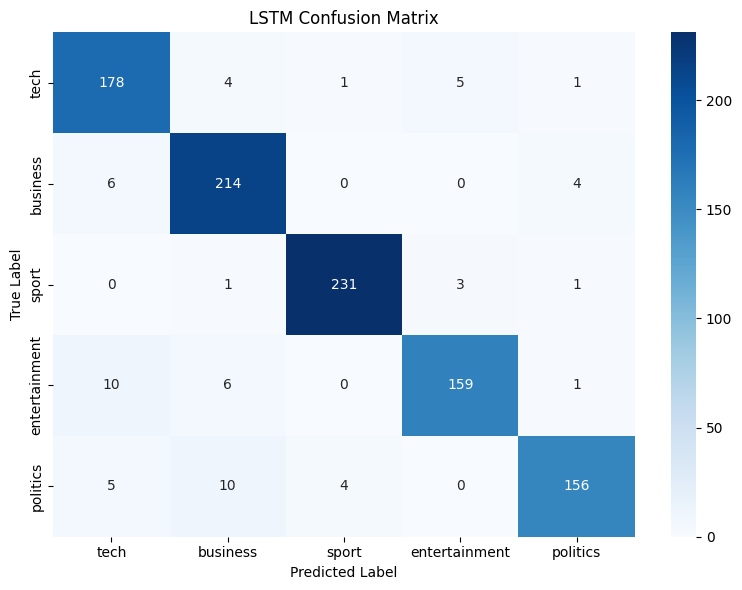

In [ ]:
# Confusion Matrix and Classification Report

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Evaluate model on test data
test_loss, test_accuracy = model.evaluate(
    X_test_pad, y_test, verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# 2. Define class names based on actual label mapping
label_mapping = (
    train[["label", "label_text"]]
    .drop_duplicates()
    .sort_values("label")
)

class_names = label_mapping["label_text"].to_list()
labels = np.arange(NUM_CLASSES)

# 3. Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_classes,
    labels=labels,
    target_names=class_names,
    zero_division=0
))

# 4. Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred_classes,
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# RNN

In [ ]:
rnn_model = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),

    layers.Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        mask_zero=True
    ),

    layers.SimpleRNN(64),

    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(NUM_CLASSES, activation='softmax')
])

rnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=['accuracy']
)

rnn_model.summary()

NameError: name 'models' is not defined

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

start_time = time.perf_counter()

history = rnn_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=15,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

training_time = time.perf_counter() - start_time

print(f"Training Time : {training_time:.2f} seconds")